# Agrupamento por área, com registro no MLflow — CPC 2023

## Objetivo

Atender às orientações da professora:

1. **Agrupar por área**, e não com a base completa.
2. **Testar vários cenários**, sempre com cotovelo (inércia), silhueta, Davies–Bouldin e ARI, e com os gráficos padronizados.
3. **Separar treino e teste** e repetir o treino com **x, z e todos os cursos** de cada área (40%, 70% e 100% do treino).
4. **Usar 2023 para o agrupamento** e 2017 e 2019 para comparar a evolução de cada indicador e do CPC.
5. **Registrar os experimentos no MLflow.**

## Desenho do experimento

| Fator | Valores |
|---|---|
| Áreas | As 8 com curso da PUC-Rio: Civil (451 cursos), Produção (300), Arquitetura (266), Mecânica (245), Elétrica (234), Ambiental (109), Química (107), Controle e Automação (93) |
| Cenários | C1 CPC global · C2 8 indicadores · C3 4 dimensões · C4 PCA 2D · C5 7 indicadores, sem Regime de Trabalho |
| K | 2 a 8, desde que haja pelo menos 10 cursos de treino por grupo |
| Treino | 80% da área, dividido em amostras aninhadas de 40%, 70% e 100% |
| Teste | 20% da área, nunca usado para ajustar escalonamento, PCA ou K-means |
| Divisões | 10 sementes (42 a 51) por área |
| Sensibilidade (C2 e C5, 100%) | Escalonadores MinMax e Robust; algoritmos k-medoids e Ward |
| Métricas | Inércia, silhueta (treino e teste), Davies–Bouldin, ARI entre divisões, Jaccard dos pares da PUC-Rio, ganho sobre dados sem grupos |

**Regra para escolher K** (em cada área e cenário, com 100% do treino): entre os K com ARI médio de pelo menos 0,80, o de maior ganho sobre dados simulados sem grupos. Se nenhum K atingir 0,80, usa-se o de maior ganho. No C1, que tem uma única variável, a referência coincide com os próprios dados, e por isso usa-se a maior silhueta no teste.

## Principais resultados

| Pergunta | Resposta |
|---|---|
| Agrupar por área melhora a silhueta? | Não. No C2, a silhueta no teste fica entre 0,15 e 0,26, contra 0,24 na base completa. |
| Em que áreas há estrutura? | Mais clara em Civil, Arquitetura e Produção. Moderada em Mecânica, Elétrica e Química. Ausente em Ambiental e em Controle e Automação. |
| O tamanho do treino importa? | A silhueta quase não muda, mas a estabilidade cresce: na Civil, o ARI passa de 0,76 (40%) para 0,95 (100%). |
| Os grupos dependem do Regime de Trabalho? | Não. Sem ele (C5), o ganho é igual ou maior que no C2 em 7 das 8 áreas. |
| O achado sobre Regime de Trabalho se mantém por área? | Sim. É a maior diferença em relação aos pares em 6 das 8 áreas e fica abaixo da média das privadas da área nas 8. |

## Como abrir o MLflow

Num terminal, na pasta do projeto:

```
python -m mlflow ui --backend-store-uri "sqlite:///mlflow_cpc.db"
```

Depois, acesse `http://127.0.0.1:5000` no navegador e abra o experimento **CPC2023_agrupamento_por_area**.

## 1. Preparação

In [1]:
# Célula 1 — Importações e parâmetros do experimento

import itertools
import os
import time
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["GIT_PYTHON_REFRESH"] = "quiet"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from joblib import Parallel, delayed

from scipy.stats import chi2_contingency, norm, rankdata
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    pairwise_distances,
    silhouette_samples,
    silhouette_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

import mlflow
import mlflow.sklearn

# Áreas analisadas: as 8 que têm curso da PUC-Rio
AREAS = {
    5710: "Engenharia Civil",
    6208: "Engenharia de Produção",
    21: "Arquitetura e Urbanismo",
    5902: "Engenharia Mecânica",
    5806: "Engenharia Elétrica",
    6307: "Engenharia Ambiental",
    6008: "Engenharia Química",
    5814: "Engenharia de Controle e Automação"
}

CENARIOS = {
    "C1_CPC": "C1 · CPC global",
    "C2_8IND": "C2 · 8 indicadores",
    "C3_4DIM": "C3 · 4 dimensões",
    "C4_PCA": "C4 · PCA 2D",
    "C5_SEM_REGIME": "C5 · 7 indicadores (sem Regime)",
    "C6_INSUMOS": "C6 · só insumos (sem ENADE e IDD)",
    "C7_SEM_REDUNDANCIA": "C7 · 5 indicadores (sem redundância)"
}
CENARIO_PRINCIPAL = "C2_8IND"
CENARIO_BENCHMARK = "C6_INSUMOS"     # pares com insumos parecidos, para comparar ENADE e IDD
EXPERIMENTO_MLFLOW = "CPC2023_agrupamento_por_area_C1_C7"

# Cenários e variações da análise de sensibilidade (só com 100% do treino)
CENARIOS_SENSIBILIDADE = ["C2_8IND", "C5_SEM_REGIME"]
ESCALONADORES_SENS = ["MinMax", "Robust"]
ALGORITMOS_SENS = ["K-medoids", "Ward"]

PROPORCOES = [0.4, 0.7, 1.0]        # x, z e todos os cursos de treino
SEMENTES = list(range(42, 52))       # 10 divisões treino/teste por área
TEST_SIZE = 0.20
K_MAX = 8
MIN_POR_GRUPO = 10                   # K só é testado se houver >= 10 cursos por grupo
N_INIT = 10
LIMIAR_ARI = 0.80                    # estabilidade mínima para escolher K
CODIGO_IES_PUC = 528

# Gráficos de cada área: exibidos no notebook só para estas áreas (todos são salvos)
AREAS_EXIBIDAS = [5710]

INDICADORES = [
    "Enade_2023", "IDD_2023", "Mestres_2023", "Doutores_2023",
    "Regime_Trabalho_2023", "Organizacao_Didatica_2023",
    "Infraestrutura_2023", "Oportunidades_2023"
]
INDICADORES_SEM_REGIME = [c for c in INDICADORES if c != "Regime_Trabalho_2023"]
# C6: o que o curso oferece (corpo docente e condições), sem os resultados dos alunos
INDICADORES_INSUMOS = ["Mestres_2023", "Doutores_2023", "Regime_Trabalho_2023",
                       "Organizacao_Didatica_2023", "Infraestrutura_2023", "Oportunidades_2023"]
# C7: um indicador de cada par muito correlacionado (ENADE~IDD; Org. didática~Infraestrutura~Oportunidades)
INDICADORES_SEM_REDUNDANCIA = ["Enade_2023", "Mestres_2023", "Doutores_2023",
                               "Regime_Trabalho_2023", "Organizacao_Didatica_2023"]
NOMES =["ENADE", "IDD", "Mestres", "Doutores", "Regime de trabalho",
         "Organização didática", "Infraestrutura", "Oportunidades"]

pasta_saida = Path("resultados_notebook_09")
pasta_saida.mkdir(exist_ok=True)

# Identidade visual
CORES_CENARIOS = dict(zip(CENARIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
COR_PUC, COR_PARES, COR_AREA = "#002060", "#FFC000", "#9B9683"
COR_TEXTO, COR_GRADE = "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10,
    "axes.edgecolor": COR_GRADE, "axes.labelcolor": COR_TEXTO, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": COR_GRADE, "grid.linewidth": 0.7,
    "xtick.color": COR_TEXTO, "ytick.color": COR_TEXTO, "legend.frameon": False
})

print("Áreas:", len(AREAS), "| Cenários:", len(CENARIOS), "| Proporções:", PROPORCOES,
      "| Divisões:", len(SEMENTES), "| K: 2 a", K_MAX)

Áreas: 8 | Cenários: 7 | Proporções: [0.4, 0.7, 1.0] | Divisões: 10 | K: 2 a 8


In [2]:
# Célula 2 — Dados: base analítica + categoria administrativa do INEP

base = pd.read_csv("dados/processados/base_analitica_1907_cursos.csv", encoding="utf-8-sig")
base.columns = base.columns.str.replace("﻿", "", regex=False).str.strip()

inep = (
    pd.read_csv("resultados/cpc_censo_2023.csv", sep=";", encoding="utf-8-sig",
                usecols=["Código do Curso", "Categoria Administrativa"], low_memory=False)
    .drop_duplicates("Código do Curso")
)
base = base.merge(inep, on="Código do Curso", how="left", validate="one_to_one")
base["Tipo"] = np.where(base["Categoria Administrativa"].str.startswith("Pública"), "Pública", "Privada")

base = base[base["Area_2023"].isin(AREAS)].reset_index(drop=True)

resumo_areas = base.groupby("Area_2023").agg(
    Cursos=("Código do Curso", "size"),
    Públicos=("Tipo", lambda s: int((s == "Pública").sum())),
    Curso_PUC=("Código do Curso", lambda s: int(s[base.loc[s.index, "Código da IES"].eq(CODIGO_IES_PUC)].iloc[0]))
)
resumo_areas.insert(0, "Área", [AREAS[a] for a in resumo_areas.index])
resumo_areas["Treino (80%)"] = (resumo_areas["Cursos"] * (1 - TEST_SIZE)).round().astype(int)
resumo_areas["Treino 40%"] = (resumo_areas["Treino (80%)"] * 0.4).round().astype(int)
resumo_areas["Treino 70%"] = (resumo_areas["Treino (80%)"] * 0.7).round().astype(int)

print(f"Cursos nas {len(AREAS)} áreas:", len(base), "| ausentes nos indicadores:", base[INDICADORES].isna().sum().sum())
display(resumo_areas.loc[list(AREAS)])

Cursos nas 8 áreas: 1805 | ausentes nos indicadores: 0


,Área,Cursos,Públicos,Curso_PUC,Treino (80%),Treino 40%,Treino 70%
Area_2023,,,,,,,
5710,Engenharia Civil,451,110,29445,361,144,253
6208,Engenharia de Produção,300,83,44431,240,96,168
21,Arquitetura e Urbanismo,266,49,59962,213,85,149
5902,Engenharia Mecânica,245,82,23702,196,78,137
5806,Engenharia Elétrica,234,84,29446,187,75,131
6307,Engenharia Ambiental,109,66,70523,87,35,61
6008,Engenharia Química,107,49,32975,86,34,60
5814,Engenharia de Controle e Automação,93,39,32655,74,30,52


In [3]:
# Célula 3 — Funções: representação, preparação, algoritmos e referência sem grupos

ESCALAS = {"Standard": StandardScaler, "MinMax": MinMaxScaler, "Robust": RobustScaler}


def criar_dimensoes_cpc(dados):
    return pd.DataFrame({
        "ENADE": dados["Enade_2023"],
        "IDD": dados["IDD_2023"],
        "Condicoes_Formacao": (7.5 * dados["Organizacao_Didatica_2023"]
                               + 5.0 * dados["Infraestrutura_2023"]
                               + 2.5 * dados["Oportunidades_2023"]) / 15.0,
        "Corpo_Docente": (7.5 * dados["Mestres_2023"]
                          + 15.0 * dados["Doutores_2023"]
                          + 7.5 * dados["Regime_Trabalho_2023"]) / 30.0
    }, index=dados.index)


def representar(dados, cenario):
    if cenario == "C1_CPC":
        return dados[["CPC_2023"]]
    if cenario == "C3_4DIM":
        return criar_dimensoes_cpc(dados)
    if cenario == "C5_SEM_REGIME":
        return dados[INDICADORES_SEM_REGIME]
    if cenario == "C6_INSUMOS":
        return dados[INDICADORES_INSUMOS]
    if cenario == "C7_SEM_REDUNDANCIA":
        return dados[INDICADORES_SEM_REDUNDANCIA]
    return dados[INDICADORES]


def preparar(cenario, treino, outros, escala="Standard"):
    """Ajusta escalonamento (e PCA no C4) só no treino e aplica às outras bases."""
    esc = ESCALAS[escala]().fit(representar(treino, cenario))
    X_treino = esc.transform(representar(treino, cenario))
    X_outros = [esc.transform(representar(o, cenario)) for o in outros]
    if cenario == "C4_PCA":
        pca = PCA(n_components=2).fit(X_treino)
        X_treino = pca.transform(X_treino)
        X_outros = [pca.transform(x) for x in X_outros]
    return X_treino, X_outros


def k_medoides(D, k, semente, n_init=5, max_iter=50):
    gerador = np.random.default_rng(semente)
    melhor = (np.inf, None, None)
    n = len(D)
    for _ in range(n_init):
        medoides = [gerador.integers(n)]
        while len(medoides) < k:
            d_min = D[:, medoides].min(axis=1) ** 2
            medoides.append(gerador.choice(n, p=d_min / d_min.sum()))
        medoides = np.array(medoides)
        for _ in range(max_iter):
            rotulos = D[:, medoides].argmin(axis=1)
            novos = np.array([np.flatnonzero(rotulos == g)[
                D[np.ix_(rotulos == g, rotulos == g)].sum(axis=1).argmin()] for g in range(k)])
            if np.array_equal(np.sort(novos), np.sort(medoides)):
                break
            medoides = novos
        custo = D[np.arange(n), medoides[rotulos]].sum()
        if custo < melhor[0]:
            melhor = (custo, rotulos, medoides)
    return melhor[1], melhor[2]


def ajustar(algoritmo, X, k, semente):
    """Retorna rótulos do treino e os centros usados para atribuir novos cursos."""
    if algoritmo == "K-means":
        modelo = KMeans(n_clusters=k, random_state=semente, n_init=N_INIT).fit(X)
        return modelo.labels_, modelo.cluster_centers_
    if algoritmo == "Ward":
        rotulos = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        return rotulos, np.array([X[rotulos == g].mean(axis=0) for g in range(k)])
    if algoritmo == "K-medoids":
        rotulos, medoides = k_medoides(pairwise_distances(X), k, semente)
        return rotulos, X[medoides]
    raise ValueError(algoritmo)


def atribuir(X, centros):
    return pairwise_distances(X, centros).argmin(axis=1)


def metricas(X, rotulos):
    grupos = len(np.unique(rotulos))
    if grupos < 2 or grupos >= len(X):
        return np.nan, np.nan
    return silhouette_score(X, rotulos), davies_bouldin_score(X, rotulos)


def referencia_copula(X, semente):
    """Dados sem grupos com as mesmas distribuições e correlações (cópula gaussiana)."""
    gerador = np.random.default_rng(semente)
    n, p = X.shape
    escores = np.column_stack([norm.ppf((rankdata(X[:, j]) - 0.5) / n) for j in range(p)])
    R = np.atleast_2d(np.corrcoef(escores, rowvar=False)) if p > 1 else np.array([[1.0]])
    latente = gerador.multivariate_normal(np.zeros(p), R, size=n)
    u = norm.cdf(latente)
    return np.column_stack([np.quantile(X[:, j], u[:, j]) for j in range(p)])

## 2. Experimento

Cada área é processada de forma independente, em paralelo. Em cada divisão, o treino é embaralhado uma vez, e as amostras de 40%, 70% e 100% são tomadas em sequência. Assim, a amostra menor está sempre contida na maior. O escalonamento e a PCA são ajustados só na amostra de treino em uso. Os cursos de teste e os demais cursos da área são atribuídos ao centro mais próximo.

In [4]:
# Célula 4 — Experimento de uma área (todas as divisões, proporções, cenários e K)

def avaliar_area(codigo, dados):
    dados = dados.reset_index(drop=True)
    n = len(dados)
    pos_puc = int(np.flatnonzero(dados["Código da IES"].eq(CODIGO_IES_PUC))[0])
    linhas, rotulos = [], {}

    for semente in SEMENTES:
        idx_treino, idx_teste = train_test_split(np.arange(n), test_size=TEST_SIZE, random_state=semente)
        ordem = np.random.default_rng(semente).permutation(idx_treino)

        for proporcao in PROPORCOES:
            # Amostras aninhadas: os 40% estão dentro dos 70%, que estão dentro dos 100%
            sub = ordem[:int(round(proporcao * len(ordem)))]

            configs = [(c, "Standard", "K-means") for c in CENARIOS]
            if proporcao == 1.0:
                configs += [(c, e, "K-means") for c in CENARIOS_SENSIBILIDADE for e in ESCALONADORES_SENS]
                configs += [(c, "Standard", a) for c in CENARIOS_SENSIBILIDADE for a in ALGORITMOS_SENS]

            for cenario, escala, algoritmo in configs:
                X_sub, (X_teste, X_todos) = preparar(
                    cenario, dados.iloc[sub], [dados.iloc[idx_teste], dados], escala)

                base_principal = proporcao == 1.0 and escala == "Standard" and algoritmo == "K-means"
                X_nulo = referencia_copula(X_sub, semente + 1000) if base_principal else None

                for k in range(2, K_MAX + 1):
                    if len(sub) // k < MIN_POR_GRUPO:
                        break
                    rot_treino, centros = ajustar(algoritmo, X_sub, k, semente)
                    rot_teste = atribuir(X_teste, centros)
                    rot_todos = atribuir(X_todos, centros)
                    sil_tr, db_tr = metricas(X_sub, rot_treino)
                    sil_te, db_te = metricas(X_teste, rot_teste)

                    linha = {
                        "Area": codigo, "Cenario": cenario, "Escalonador": escala,
                        "Algoritmo": algoritmo, "Proporcao": proporcao, "Semente": semente, "K": k,
                        "N_treino": len(sub), "N_teste": len(idx_teste),
                        "Inercia": float(((X_sub - centros[rot_treino]) ** 2).sum()),
                        "Silhueta_treino": sil_tr, "Silhueta_teste": sil_te,
                        "DB_treino": db_tr, "DB_teste": db_te,
                        "Menor_grupo": int(np.bincount(rot_treino, minlength=k).min()),
                        "Grupos_no_teste": len(np.unique(rot_teste))
                    }
                    if X_nulo is not None:
                        rot_nulo, _ = ajustar("K-means", X_nulo, k, semente)
                        linha["Silhueta_nula"] = metricas(X_nulo, rot_nulo)[0]
                    linhas.append(linha)
                    rotulos.setdefault((cenario, escala, algoritmo, proporcao, k), {})[semente] = rot_todos

    # Estabilidade entre divisões: ARI global e Jaccard dos pares da PUC-Rio
    estabilidade = []
    for (cenario, escala, algoritmo, proporcao, k), reps in rotulos.items():
        aris, jaccards = [], []
        for a, b in itertools.combinations(sorted(reps), 2):
            ra, rb = reps[a], reps[b]
            aris.append(adjusted_rand_score(ra, rb))
            pa = set(np.flatnonzero(ra == ra[pos_puc])) - {pos_puc}
            pb = set(np.flatnonzero(rb == rb[pos_puc])) - {pos_puc}
            jaccards.append(len(pa & pb) / len(pa | pb) if pa | pb else 1.0)
        estabilidade.append({
            "Area": codigo, "Cenario": cenario, "Escalonador": escala, "Algoritmo": algoritmo,
            "Proporcao": proporcao, "K": k, "ARI_medio": np.mean(aris), "ARI_minimo": np.min(aris),
            "Jaccard_PUC": np.mean(jaccards)
        })

    return pd.DataFrame(linhas), pd.DataFrame(estabilidade)

In [5]:
# Célula 5 — Executar as 8 áreas em paralelo

inicio = time.time()

resultados = Parallel(n_jobs=4)(
    delayed(avaliar_area)(codigo, base[base["Area_2023"].eq(codigo)])
    for codigo in AREAS
)

log = pd.concat([r[0] for r in resultados], ignore_index=True)
estab = pd.concat([r[1] for r in resultados], ignore_index=True)

chaves = ["Area", "Cenario", "Escalonador", "Algoritmo", "Proporcao", "K"]
resumo = (
    log.groupby(chaves)
    .agg(Silhueta_treino=("Silhueta_treino", "mean"),
         Silhueta_teste=("Silhueta_teste", "mean"),
         Silhueta_teste_dp=("Silhueta_teste", "std"),
         Silhueta_nula=("Silhueta_nula", "mean"),
         DB_teste=("DB_teste", "mean"),
         Inercia=("Inercia", "mean"),
         Menor_grupo=("Menor_grupo", "min"),
         N_treino=("N_treino", "first"))
    .reset_index()
    .merge(estab, on=chaves)
)
resumo["Ganho"] = resumo["Silhueta_treino"] - resumo["Silhueta_nula"]

print(f"Execuções (modelos ajustados nos dados reais): {len(log):,}".replace(",", "."))
print(f"Configurações resumidas: {len(resumo):,}".replace(",", "."))
print(f"Tempo: {(time.time() - inicio) / 60:.1f} min")

Execuções (modelos ajustados nos dados reais): 14.340
Configurações resumidas: 1.434
Tempo: 7.9 min


## 3. Escolha de K e comparação dos cenários

In [6]:
# Célula 6 — Escolha de K por área e cenário (100% do treino, StandardScaler, K-means)

def escolher_k(tabela, cenario):
    """Regra: entre os K com ARI médio >= 0,80, o de maior ganho sobre os dados sem grupos.
    No C1 (uma variável) a referência sem grupos coincide com os dados; usa-se a silhueta no teste."""
    criterio = "Silhueta_teste" if cenario == "C1_CPC" else "Ganho"
    candidatos = tabela[tabela["ARI_medio"] >= LIMIAR_ARI]
    if candidatos.empty:
        candidatos = tabela
    return int(candidatos.loc[candidatos[criterio].idxmax(), "K"])


base_principal = resumo[(resumo["Escalonador"] == "Standard") & (resumo["Algoritmo"] == "K-means")]
completo = base_principal[base_principal["Proporcao"] == 1.0]

linhas = []
for (area, cenario), tabela in completo.groupby(["Area", "Cenario"]):
    k = escolher_k(tabela, cenario)
    linha = tabela[tabela["K"] == k].iloc[0]
    linhas.append({
        "Area": area, "Área": AREAS[area], "Cenario": cenario, "K_escolhido": k,
        "Silhueta_teste": linha["Silhueta_teste"], "Ganho": linha["Ganho"],
        "DB_teste": linha["DB_teste"], "ARI_medio": linha["ARI_medio"], "Jaccard_PUC": linha["Jaccard_PUC"]
    })
escolhas = pd.DataFrame(linhas)

k_principal = escolhas[escolhas["Cenario"] == CENARIO_PRINCIPAL].set_index("Area")["K_escolhido"].to_dict()

print("K escolhido por área e cenário")
display(escolhas.pivot(index="Área", columns="Cenario", values="K_escolhido").loc[list(AREAS.values())])

print("Cenário principal (C2) no K escolhido")
display(
    escolhas[escolhas["Cenario"] == CENARIO_PRINCIPAL]
    .set_index("Área")[["K_escolhido", "Silhueta_teste", "Ganho", "DB_teste", "ARI_medio", "Jaccard_PUC"]]
    .loc[list(AREAS.values())].round(3)
)

K escolhido por área e cenário


Cenario,C1_CPC,C2_8IND,C3_4DIM,C4_PCA,C5_SEM_REGIME,C6_INSUMOS,C7_SEM_REDUNDANCIA
Área,,,,,,,
Engenharia Civil,2,4,4,3,4,4,6
Engenharia de Produção,3,4,4,4,4,3,2
Arquitetura e Urbanismo,2,4,4,6,4,3,5
Engenharia Mecânica,2,3,2,3,4,2,6
Engenharia Elétrica,2,3,2,3,3,2,5
Engenharia Ambiental,6,5,5,2,2,4,3
Engenharia Química,6,4,4,2,4,3,3
Engenharia de Controle e Automação,3,2,4,3,2,6,2


Cenário principal (C2) no K escolhido


,K_escolhido,Silhueta_teste,Ganho,DB_teste,ARI_medio,Jaccard_PUC
Área,,,,,,
Engenharia Civil,4,0.258,0.066,1.236,0.948,0.967
Engenharia de Produção,4,0.219,0.053,1.288,0.825,0.852
Arquitetura e Urbanismo,4,0.232,0.053,1.335,0.942,0.937
Engenharia Mecânica,3,0.245,0.023,1.358,0.865,0.425
Engenharia Elétrica,3,0.229,0.027,1.374,0.821,0.507
Engenharia Ambiental,5,0.151,-0.012,1.171,0.601,0.341
Engenharia Química,4,0.241,0.037,1.032,0.866,0.602
Engenharia de Controle e Automação,2,0.203,0.006,1.505,0.754,0.887


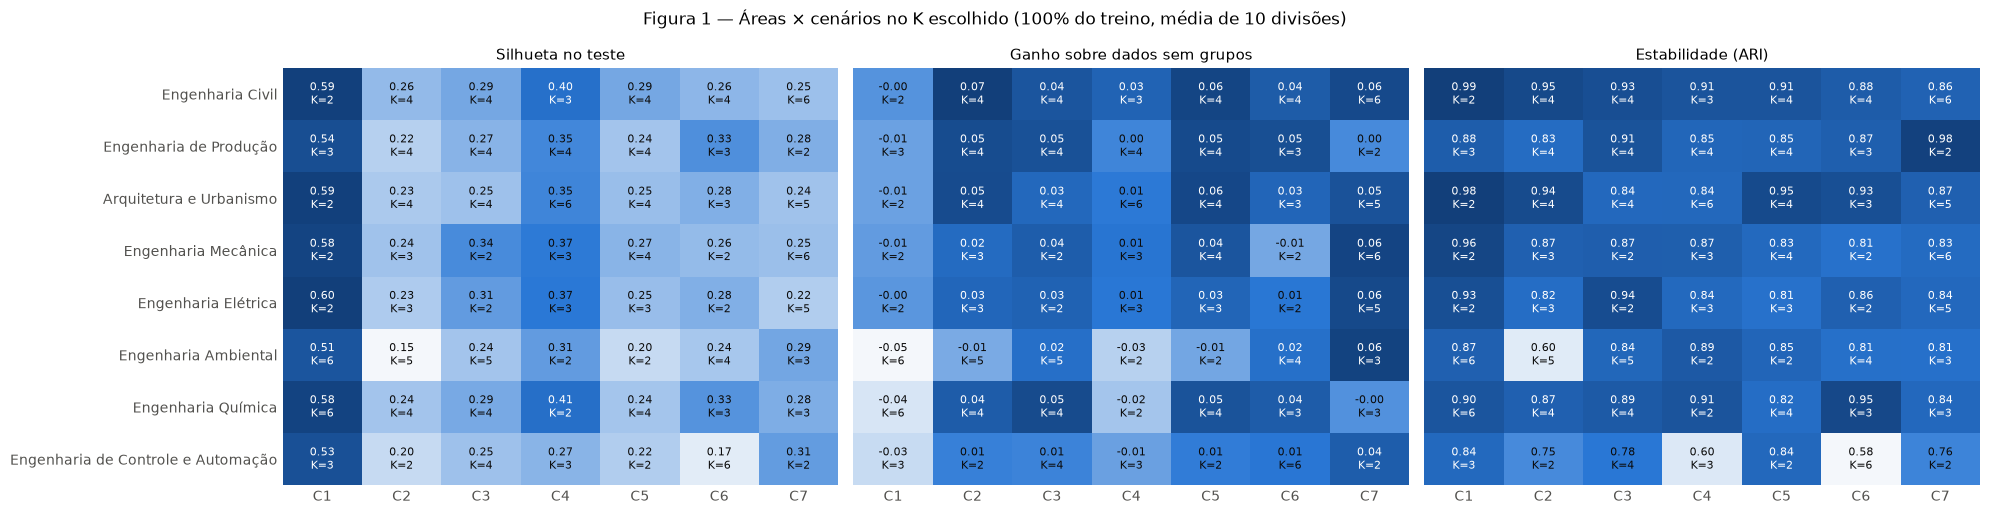

In [7]:
# Célula 7 — Figura 1: visão geral das áreas no K escolhido de cada cenário

metricas_vg = [("Silhueta_teste", "Silhueta no teste"), ("Ganho", "Ganho sobre dados sem grupos"),
               ("ARI_medio", "Estabilidade (ARI)")]
cmap_seq = LinearSegmentedColormap.from_list("azul", ["#f4f7fb", "#2a78d6", "#123f7a"])

fig, eixos = plt.subplots(1, 3, figsize=(20, 5.2))
for ax, (coluna, titulo) in zip(eixos, metricas_vg):
    tabela = escolhas.pivot(index="Área", columns="Cenario", values=coluna).loc[list(AREAS.values()), list(CENARIOS)]
    valores = tabela.to_numpy(dtype=float)
    vmin, vmax = np.nanmin(valores), np.nanmax(valores)
    ax.imshow(valores, cmap=cmap_seq, aspect="auto", vmin=vmin, vmax=vmax)
    k_tab = escolhas.pivot(index="Área", columns="Cenario", values="K_escolhido").loc[tabela.index, tabela.columns]
    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):
            if np.isfinite(valores[i, j]):
                intensidade = (valores[i, j] - vmin) / (vmax - vmin)
                ax.text(j, i, f"{valores[i, j]:.2f}\nK={k_tab.iat[i, j]}", ha="center", va="center", fontsize=8,
                        color="white" if intensidade > 0.55 else "#0b0b0b")
    ax.set_xticks(range(len(CENARIOS)), [c.split("_")[0] for c in CENARIOS])
    ax.set_yticks(range(len(tabela)), tabela.index if ax is eixos[0] else [""] * len(tabela))
    ax.set_title(titulo)
    ax.grid(visible=False)
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)

fig.suptitle("Figura 1 — Áreas × cenários no K escolhido (100% do treino, média de 10 divisões)", fontsize=12)
plt.tight_layout()
fig.savefig(pasta_saida / "figura_1_visao_geral_areas.png", dpi=200, bbox_inches="tight")
plt.show()

V de Cramér entre os grupos e pública × privada (0 = nenhuma relação, 1 = total)


Cenario,C1_CPC,C2_8IND,C3_4DIM,C4_PCA,C5_SEM_REGIME,C6_INSUMOS,C7_SEM_REDUNDANCIA
Área,,,,,,,
Engenharia Civil,0.52,0.79,0.78,0.74,0.79,0.45,0.80
Engenharia de Produção,0.43,0.62,0.57,0.68,0.58,0.46,0.30
Arquitetura e Urbanismo,0.44,0.74,0.79,0.77,0.74,0.42,0.77
Engenharia Mecânica,0.55,0.78,0.60,0.79,0.74,0.30,0.83
Engenharia Elétrica,0.51,0.71,0.59,0.69,0.68,0.45,0.73
Engenharia Ambiental,0.47,0.59,0.52,0.21,0.09,0.44,0.52
Engenharia Química,0.30,0.70,0.72,0.68,0.67,0.65,0.83
Engenharia de Controle e Automação,0.45,0.27,0.57,0.43,0.14,0.51,0.42


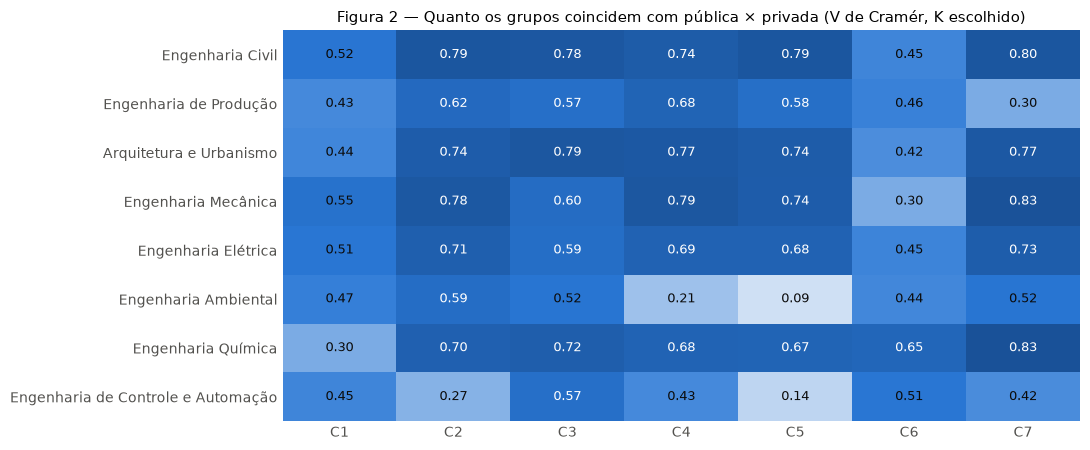

In [8]:
# Célula — Validação externa: os grupos coincidem com pública × privada?

def v_de_cramer(a, b):
    tabela = pd.crosstab(a, b)
    if min(tabela.shape) < 2:
        return np.nan
    qui2 = chi2_contingency(tabela, correction=False)[0]
    return np.sqrt(qui2 / (tabela.to_numpy().sum() * (min(tabela.shape) - 1)))


linhas = []
for codigo in AREAS:
    dados = base[base["Area_2023"].eq(codigo)].reset_index(drop=True)
    idx_treino, _ = train_test_split(np.arange(len(dados)), test_size=TEST_SIZE, random_state=SEMENTES[0])
    for cen in CENARIOS:
        k = int(escolhas[(escolhas["Area"] == codigo) & (escolhas["Cenario"] == cen)]["K_escolhido"].iloc[0])
        X_treino, (X_todos,) = preparar(cen, dados.iloc[idx_treino], [dados])
        _, centros = ajustar("K-means", X_treino, k, SEMENTES[0])
        grupos = atribuir(X_todos, centros)
        linhas.append({"Area": codigo, "Área": AREAS[codigo], "Cenario": cen, "K": k,
                       "V pública × privada": v_de_cramer(grupos, dados["Tipo"]),
                       "V categoria (7)": v_de_cramer(grupos, dados["Categoria Administrativa"])})
validacao = pd.DataFrame(linhas)

print("V de Cramér entre os grupos e pública × privada (0 = nenhuma relação, 1 = total)")
tabela_v = validacao.pivot(index="Área", columns="Cenario", values="V pública × privada").loc[list(AREAS.values()), list(CENARIOS)]
display(tabela_v.round(2))

fig, ax = plt.subplots(figsize=(11, 4.6))
cmap_v = LinearSegmentedColormap.from_list("azul", ["#f4f7fb", "#2a78d6", "#123f7a"])
ax.imshow(tabela_v.to_numpy(dtype=float), cmap=cmap_v, vmin=0, vmax=1, aspect="auto")
for i in range(tabela_v.shape[0]):
    for j in range(tabela_v.shape[1]):
        v = tabela_v.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else "#0b0b0b")
ax.set_xticks(range(len(CENARIOS)), [c.split("_")[0] for c in CENARIOS])
ax.set_yticks(range(len(tabela_v)), tabela_v.index)
ax.grid(visible=False); ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Figura 2 — Quanto os grupos coincidem com pública × privada (V de Cramér, K escolhido)")
plt.tight_layout()
fig.savefig(pasta_saida / "figura_2_validacao_externa.png", dpi=200, bbox_inches="tight")
plt.show()

### Leitura

- **C1 e C4 têm a silhueta mais alta, mas sem estrutura real.** No C1, a silhueta vai de 0,51 a 0,60, e o ganho sobre dados sem grupos é zero ou negativo em todas as áreas. No C4, a silhueta vai de 0,27 a 0,41, com ganho de no máximo 0,03. É o mesmo efeito visto na base completa: poucas dimensões elevam a silhueta por si só.
- **C2, C3 e C5 mostram estrutura acima da referência**, com ganhos parecidos entre si.
- **O Regime de Trabalho não define os grupos.** Sem ele (C5), o ganho é igual ou maior que no C2 em 7 das 8 áreas.
- **As áreas se dividem em três situações no C2:**
  - Estrutura mais clara (ganho ≥ 0,05 e ARI ≥ 0,82): Civil (K=4), Arquitetura (K=4) e Produção (K=4).
  - Estrutura moderada (ganho de 0,02 a 0,04): Mecânica (K=3), Elétrica (K=3) e Química (K=4).
  - Sem estrutura: Ambiental (ganho −0,012; nenhum K atinge ARI de 0,80, e o K=5 vem da regra alternativa) e Controle e Automação (ganho 0,006; ARI 0,75). São áreas pequenas, com 109 e 93 cursos.
- **Agrupar por área não aumentou a silhueta** (0,15 a 0,26 no C2, contra 0,24 na base completa), mas tornou a comparação mais pertinente, porque os pares passam a ser da mesma área.

## 4. Modelo final por área e diagnóstico da PUC-Rio

O modelo final de cada área usa o C2 no K escolhido. Ele é treinado em 80% dos cursos (divisão da semente 42), avaliado nos 20% de teste e depois aplicado a todos os cursos da área para identificar os pares da PUC-Rio.

In [9]:
# Célula 8 — Modelo final por área: C2 no K escolhido, treinado em 80% e avaliado no teste

modelos_finais, diagnostico, pares_por_area = {}, [], {}

for codigo in AREAS:
    dados = base[base["Area_2023"].eq(codigo)].reset_index(drop=True)
    pos_puc = int(np.flatnonzero(dados["Código da IES"].eq(CODIGO_IES_PUC))[0])
    k = k_principal[codigo]

    idx_treino, idx_teste = train_test_split(np.arange(len(dados)), test_size=TEST_SIZE, random_state=SEMENTES[0])
    modelo = Pipeline([
        ("escalonador", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, random_state=SEMENTES[0], n_init=20))
    ]).fit(dados.loc[idx_treino, INDICADORES])

    X_todos = modelo["escalonador"].transform(dados[INDICADORES])
    grupos = modelo.predict(dados[INDICADORES])
    sil_ind = silhouette_samples(X_todos, grupos)
    dist = np.linalg.norm(X_todos - modelo["kmeans"].cluster_centers_[grupos], axis=1)

    g = grupos[pos_puc]
    no_grupo = grupos == g
    pares = np.flatnonzero(no_grupo & (np.arange(len(dados)) != pos_puc))
    privadas = np.flatnonzero(dados["Tipo"].eq("Privada").to_numpy() & (np.arange(len(dados)) != pos_puc))

    modelos_finais[codigo] = {"modelo": modelo, "dados": dados, "grupos": grupos, "pos_puc": pos_puc,
                              "idx_treino": idx_treino, "idx_teste": idx_teste, "X": X_todos, "sil": sil_ind}
    pares_por_area[codigo] = pares

    sil_te, db_te = metricas(X_todos[idx_teste], grupos[idx_teste])
    regime = dados.loc[pos_puc, "Regime_Trabalho_2023"]
    diferencas = dados.loc[pos_puc, INDICADORES].astype(float) - dados.loc[pares, INDICADORES].mean()
    maior = diferencas.abs().idxmax()

    diagnostico.append({
        "Area": codigo, "Área": AREAS[codigo], "Curso PUC": dados.loc[pos_puc, "Código do Curso"],
        "K": k, "Silhueta teste": sil_te, "DB teste": db_te,
        "Grupo PUC": g, "Pares": len(pares), "% públicos nos pares": 100 * dados.loc[pares, "Tipo"].eq("Pública").mean(),
        "Silhueta PUC": sil_ind[pos_puc],
        "Percentil distância PUC": 100 * np.mean(dist[no_grupo] <= dist[pos_puc]),
        "Maior diferença": f"{NOMES[INDICADORES.index(maior)]} ({diferencas[maior]:+.2f})",
        "Regime − pares": regime - dados.loc[pares, "Regime_Trabalho_2023"].mean(),
        "Regime − privadas da área": regime - dados.loc[privadas, "Regime_Trabalho_2023"].mean()
    })

diagnostico = pd.DataFrame(diagnostico).set_index("Área")
print("Diagnóstico da PUC-Rio por área (C2, K escolhido, modelo treinado em 80% dos cursos)")
display(diagnostico.drop(columns="Area").round(3))

Diagnóstico da PUC-Rio por área (C2, K escolhido, modelo treinado em 80% dos cursos)


,Curso PUC,K,Silhueta teste,DB teste,Grupo PUC,Pares,% públicos nos pares,Silhueta PUC,Percentil distância PUC,Maior diferença,Regime − pares,Regime − privadas da área
Área,,,,,,,,,,,,
Engenharia Civil,29445,4,0.254,1.181,1,91,93.407,0.152,92.391,Regime de trabalho (-2.47),-2.466,-1.319
Engenharia de Produção,44431,4,0.187,1.480,3,88,10.227,0.011,98.876,Regime de trabalho (-2.24),-2.243,-1.835
Arquitetura e Urbanismo,59962,4,0.238,1.359,3,45,2.222,0.029,91.304,Regime de trabalho (-2.55),-2.551,-3.657
Engenharia Mecânica,23702,3,0.282,1.396,2,71,91.549,0.061,95.833,Regime de trabalho (-2.60),-2.597,-1.305
Engenharia Elétrica,29446,3,0.260,1.229,1,71,87.324,0.142,83.333,Regime de trabalho (-1.93),-1.931,-0.784
Engenharia Ambiental,70523,5,0.078,1.296,3,12,8.333,-0.122,69.231,Doutores (+1.63),1.033,-0.556
Engenharia Química,32975,4,0.163,1.376,2,45,11.111,-0.046,80.435,Organização didática (-1.48),-1.363,-1.172
Engenharia de Controle e Automação,32655,2,0.178,1.661,0,51,54.902,0.155,55.769,Regime de trabalho (-1.66),-1.659,-0.796


In [10]:
# Célula — Composição dos pares da PUC-Rio por categoria administrativa (C2)

linhas = {}
for codigo in AREAS:
    dados = modelos_finais[codigo]["dados"]
    linhas[AREAS[codigo]] = 100 * dados.loc[pares_por_area[codigo], "Categoria Administrativa"].value_counts(normalize=True)
composicao_pares = pd.DataFrame(linhas).T.fillna(0).loc[list(AREAS.values())]
composicao_pares.insert(0, "Pares", [len(pares_por_area[c]) for c in AREAS])

print("% dos pares da PUC-Rio (mesma área e grupo no C2) em cada categoria administrativa")
display(composicao_pares.round(1))

% dos pares da PUC-Rio (mesma área e grupo no C2) em cada categoria administrativa


Categoria Administrativa,Pares,Comunitária/Confessional,Especial,Privada com fins lucrativos,Privada sem fins lucrativos,Pública Estadual,Pública Federal,Pública Municipal
Engenharia Civil,91,2.2,0.0,3.3,1.1,22.0,71.4,0.0
Engenharia de Produção,88,33.0,1.1,23.9,31.8,4.5,4.5,1.1
Arquitetura e Urbanismo,45,13.3,0.0,55.6,28.9,0.0,0.0,2.2
Engenharia Mecânica,71,5.6,0.0,1.4,1.4,15.5,76.1,0.0
Engenharia Elétrica,71,9.9,0.0,2.8,0.0,16.9,70.4,0.0
Engenharia Ambiental,12,41.7,0.0,33.3,16.7,8.3,0.0,0.0
Engenharia Química,45,53.3,0.0,17.8,17.8,0.0,11.1,0.0
Engenharia de Controle e Automação,51,19.6,0.0,17.6,7.8,5.9,49.0,0.0


In [11]:
# Célula — Benchmarking (C6): ENADE, IDD e CPC da PUC-Rio entre cursos com insumos parecidos

modelos_c6, linhas = {}, []
for codigo in AREAS:
    info = modelos_finais[codigo]
    dados, pos, idx_treino = info["dados"], info["pos_puc"], info["idx_treino"]
    k = int(escolhas[(escolhas["Area"] == codigo) & (escolhas["Cenario"] == CENARIO_BENCHMARK)]["K_escolhido"].iloc[0])

    modelo = Pipeline([
        ("escalonador", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, random_state=SEMENTES[0], n_init=20))
    ]).fit(dados.loc[idx_treino, INDICADORES_INSUMOS])
    modelos_c6[codigo] = modelo
    grupos = modelo.predict(dados[INDICADORES_INSUMOS])
    pares = np.flatnonzero((grupos == grupos[pos]) & (np.arange(len(dados)) != pos))

    for coluna, nome in [("Enade_2023", "ENADE"), ("IDD_2023", "IDD"), ("CPC_2023", "CPC")]:
        valor = dados.loc[pos, coluna]
        valores_pares = dados.loc[pares, coluna]
        linhas.append({
            "Area": codigo, "Área": AREAS[codigo], "Indicador": nome, "K": k, "Pares": len(pares),
            "% públicos nos pares": 100 * dados.loc[pares, "Tipo"].eq("Pública").mean(),
            "PUC-Rio": valor, "Média dos pares": valores_pares.mean(),
            "Diferença": valor - valores_pares.mean(),
            "Percentil nos pares": 100 * (valores_pares < valor).mean(),
            "Média da área": dados.drop(index=pos)[coluna].mean()
        })
benchmark = pd.DataFrame(linhas)

print("PUC-Rio entre cursos da mesma área com corpo docente e condições parecidos (C6)")
display(benchmark.pivot(index="Área", columns="Indicador", values="Percentil nos pares")
        .loc[list(AREAS.values()), ["ENADE", "IDD", "CPC"]].round(0)
        .rename(columns=lambda c: f"{c}: acima de % dos pares"))
display(benchmark.set_index(["Área", "Indicador"]).drop(columns="Area").round(2))

PUC-Rio entre cursos da mesma área com corpo docente e condições parecidos (C6)


Indicador,ENADE: acima de % dos pares,IDD: acima de % dos pares,CPC: acima de % dos pares
Área,,,
Engenharia Civil,75.0,77.0,74.0
Engenharia de Produção,98.0,45.0,58.0
Arquitetura e Urbanismo,98.0,50.0,77.0
Engenharia Mecânica,96.0,91.0,92.0
Engenharia Elétrica,97.0,64.0,82.0
Engenharia Ambiental,57.0,30.0,30.0
Engenharia Química,96.0,69.0,64.0
Engenharia de Controle e Automação,39.0,14.0,18.0


K  Pares  % públicos nos pares  \
Área                               Indicador                                   
Engenharia Civil                   ENADE      4    159                 48.43   
                                   IDD        4    159                 48.43   
                                   CPC        4    159                 48.43   
Engenharia de Produção             ENADE      3    101                  8.91   
                                   IDD        3    101                  8.91   
                                   CPC        3    101                  8.91   
Arquitetura e Urbanismo            ENADE      3     56                  3.57   
                                   IDD        3     56                  3.57   
                                   CPC        3     56                  3.57   
Engenharia Mecânica                ENADE      2    125                 20.00   
                                   IDD        2    125                 20.00   
                                   CPC        2    125                 20.00   
Engenharia Elétrica                ENADE      2     90                  8.89   
                                   IDD        2     90                  8.89   
                                   CPC        2     90                  8.89   
Engenharia Ambiental               ENADE      4     47                 74.47   
                                   IDD        4     47                 74.47   
                                   CPC        4     47                 74.47   
Engenharia Química                 ENADE      3     45                 11.11   
                                   IDD        3     45                 11.11   
                                   CPC        3     45                 11.11   
Engenharia de Controle e Automação ENADE      6     28                 57.14   
                                   IDD        6     28                 57.14   
                                   CPC        6     28                 57.14   

                                              PUC-Rio  Média dos pares  \
Área                               Indicador                             
Engenharia Civil                   ENADE         3.93             2.78   
                                   IDD           3.83             2.67   
                                   CPC           3.76             3.16   
Engenharia de Produção             ENADE         3.96             2.52   
                                   IDD           2.41             2.65   
                                   CPC           3.18             3.14   
Arquitetura e Urbanismo            ENADE         3.53             2.35   
                                   IDD           2.36             2.47   
                                   CPC           2.69             2.33   
Engenharia Mecânica                ENADE         4.19             2.34   
                                   IDD           3.78             2.52   
                                   CPC           3.81             2.94   
Engenharia Elétrica                ENADE         3.55             2.12   
                                   IDD           2.81             2.57   
                                   CPC           3.38             2.89   
Engenharia Ambiental               ENADE         2.87             2.70   
                                   IDD           1.74             2.50   
                                   CPC           2.81             3.05   
Engenharia Química                 ENADE         3.12             2.25   
                                   IDD           2.65             2.30   
                                   CPC           3.20             3.04   
Engenharia de Controle e Automação ENADE         2.77             2.99   
                                   IDD           1.78             2.56   
                                   CPC           2.71             3.19   

                                        

### Leitura

- **Regime de Trabalho é a maior diferença em 6 das 8 áreas**, sempre abaixo dos pares (de −1,66 a −2,60). As exceções são Química, em que a maior diferença é Organização Didática (−1,48), com Regime logo atrás (−1,36), e Ambiental (Doutores, +1,63).
- **Contra todas as privadas da mesma área, o Regime da PUC-Rio fica abaixo nas 8 áreas** (de −0,56 a −3,66).
- **A composição dos pares muda muito:** de 2% de cursos públicos (Arquitetura) a 93% (Civil). Isso precisa constar do diagnóstico de cada curso.
- **Os cursos da PUC-Rio continuam na fronteira dos grupos:** a silhueta individual vai de −0,12 a 0,16.
- **Ambiental não deve ser interpretada:** são só 12 pares, a silhueta da PUC-Rio é negativa e a área não mostrou estrutura.
- **A estabilidade dos pares da PUC-Rio varia por área.** O Jaccard é alto na Civil (0,97), em Arquitetura (0,94), em Controle e Automação (0,89) e em Produção (0,85). É baixo em Química (0,60), Elétrica (0,51), Mecânica (0,43) e Ambiental (0,34).

## 5. Evolução 2017 → 2019 → 2023

Os pares são os cursos do mesmo grupo de 2023. Por isso, a comparação mostra como chegaram a 2023 os cursos que hoje têm perfil parecido com o da PUC-Rio.

In [12]:
# Célula 9 — Evolução 2017 → 2019 → 2023: PUC-Rio, pares (grupo de 2023) e área

COMPONENTES = ["Enade", "IDD", "Mestres", "Doutores", "Regime_Trabalho",
               "Organizacao_Didatica", "Infraestrutura", "Oportunidades", "CPC"]
NOMES_EVOL = NOMES + ["CPC (contínuo)"]
ANOS = [2017, 2019, 2023]

linhas = []
for codigo, info in modelos_finais.items():
    dados, pos, pares = info["dados"], info["pos_puc"], pares_por_area[codigo]
    for comp, nome in zip(COMPONENTES, NOMES_EVOL):
        for ano in ANOS:
            coluna = f"{comp}_{ano}"
            linhas.append({"Area": codigo, "Indicador": nome, "Ano": ano,
                           "PUC-Rio": dados.loc[pos, coluna],
                           "Pares": dados.loc[pares, coluna].mean(),
                           "Área": dados[coluna].mean()})
evolucao = pd.DataFrame(linhas)

variacao = (
    evolucao.pivot_table(index=["Area", "Indicador"], columns="Ano", values="PUC-Rio")
    .assign(**{"Variação 2017→2023 (PUC-Rio)": lambda t: t[2023] - t[2017]})
)
print("PUC-Rio: CPC contínuo por ciclo e área")
display(
    evolucao[evolucao["Indicador"] == "CPC (contínuo)"]
    .pivot_table(index="Area", columns="Ano", values=["PUC-Rio", "Pares", "Área"])
    .rename(index=AREAS).round(2)
)

PUC-Rio: CPC contínuo por ciclo e área


PUC-Rio             Pares              \
Ano                                   2017  2019  2023  2017  2019  2023   
Area                                                                       
Arquitetura e Urbanismo               2.65  2.33  2.69  2.40  2.34  2.27   
Engenharia Civil                      3.18  3.05  3.76  3.07  3.28  3.75   
Engenharia Elétrica                   3.50  3.36  3.38  3.12  3.24  3.68   
Engenharia de Controle e Automação    3.46  3.07  2.71  3.12  3.20  3.20   
Engenharia Mecânica                   3.18  2.54  3.81  3.03  3.09  3.61   
Engenharia Química                    3.40  3.32  3.20  3.02  2.95  3.04   
Engenharia de Produção                2.91  3.12  3.18  2.76  2.97  3.20   
Engenharia Ambiental                  3.28  2.38  2.81  2.76  2.69  2.42   

                                    Área              
Ano                                 2017  2019  2023  
Area                                                  
Arquitetura e Urbanismo             2.70  2.68  2.96  
Engenharia Civil                    2.67  2.84  2.80  
Engenharia Elétrica                 2.81  2.82  2.98  
Engenharia de Controle e Automação  2.88  2.94  2.79  
Engenharia Mecânica                 2.68  2.67  2.86  
Engenharia Química                  3.07  2.93  3.00  
Engenharia de Produção              2.71  2.86  2.95  
Engenharia Ambiental                3.02  3.01  3.08

### Leitura (CPC contínuo da PUC-Rio)

- **Subiu:** Civil (3,18 → 3,76), Mecânica (3,18 → 3,81) e Produção (2,91 → 3,18).
- **Ficou estável:** Arquitetura (2,65 → 2,69).
- **Caiu:** Elétrica (3,50 → 3,38), Química (3,40 → 3,20), Ambiental (3,28 → 2,81) e Controle e Automação (3,46 → 2,71).
- **Regime de Trabalho na Civil:** passou de 3,30 em 2017 para 3,71 em 2019 e caiu para 2,46 em 2023, enquanto os pares ficaram perto de 4,9 nos três ciclos.

**Cuidado:** o INEP mudou detalhes do cálculo entre ciclos. As variações devem ser lidas como mudanças nas notas, não necessariamente como mudanças na qualidade.

## 6. Gráficos por área

Para cada área são gerados sete gráficos, salvos em `resultados_notebook_09/<área>/` e registrados no MLflow:

| Arquivo | Conteúdo |
|---|---|
| A | Cotovelo (inércia), silhueta no teste, Davies–Bouldin e ARI por K, para os 5 cenários |
| B | Ganho sobre dados sem grupos por K |
| C | Curva de aprendizado: 40%, 70% e 100% do treino |
| D | Sensibilidade ao escalonador e ao algoritmo |
| E | Modelo final: silhueta individual, centróides e mapa 2D com a PUC-Rio |
| F | PUC-Rio × pares × área nos 8 indicadores |
| G | Evolução 2017–2019–2023 dos 8 indicadores e do CPC |

No notebook, aparecem só os gráficos da Engenharia Civil. Para exibir outra área, inclua o código dela em `AREAS_EXIBIDAS`, na Célula 1.

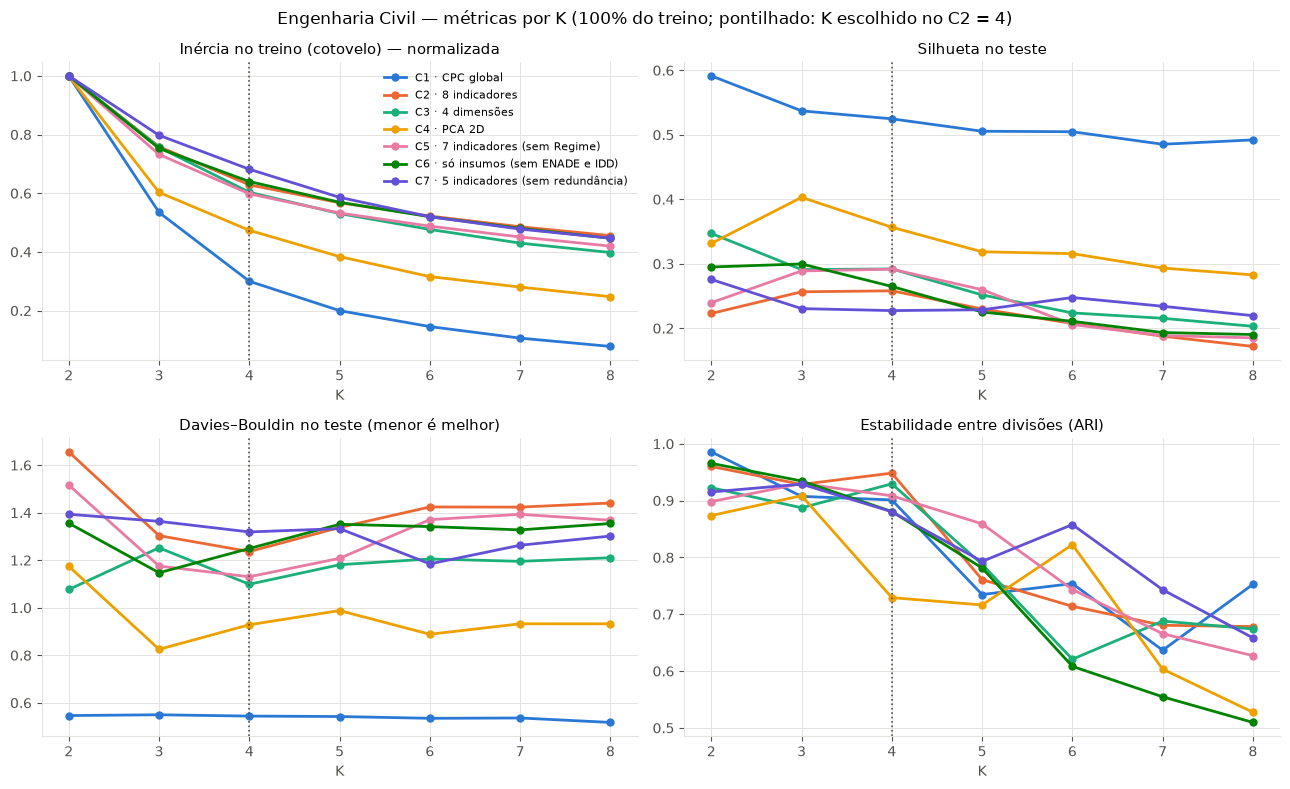

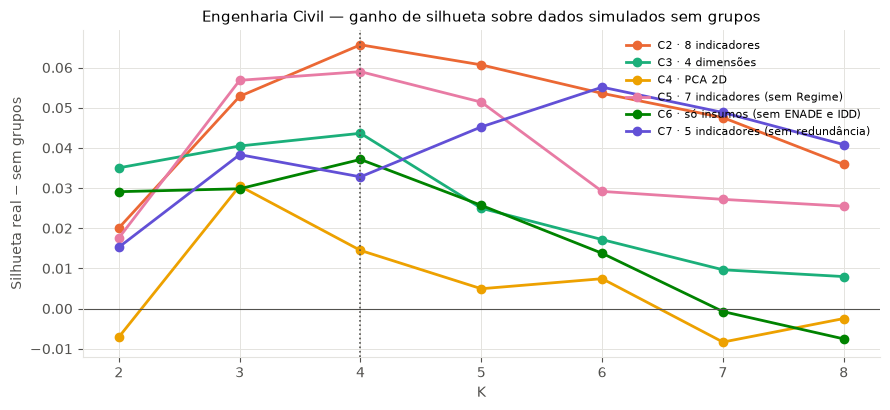

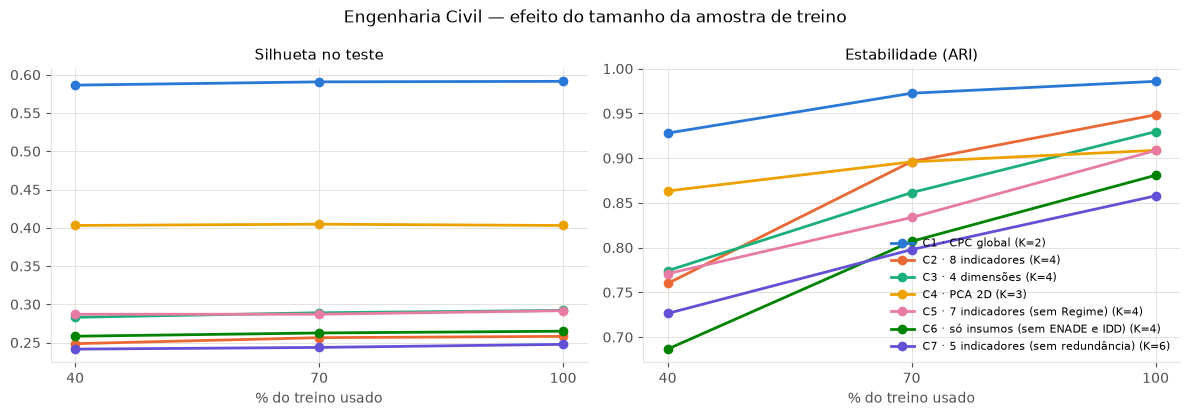

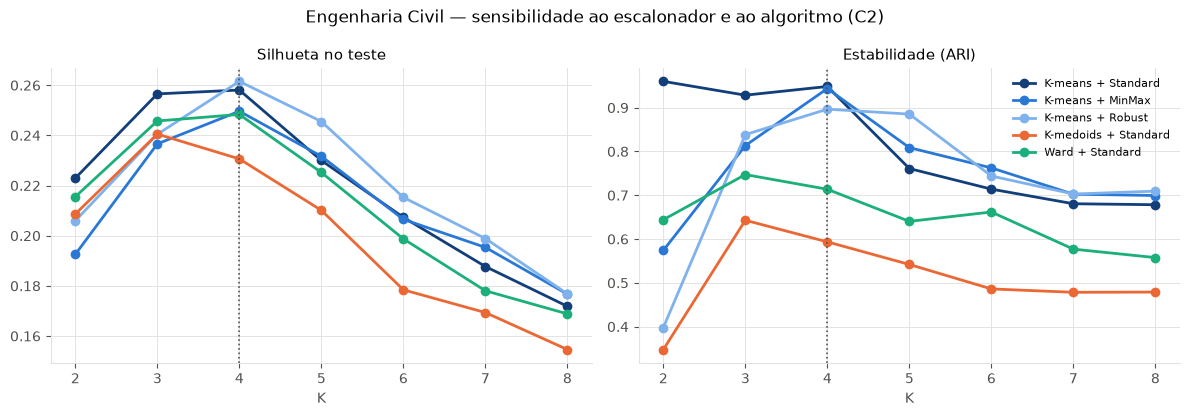

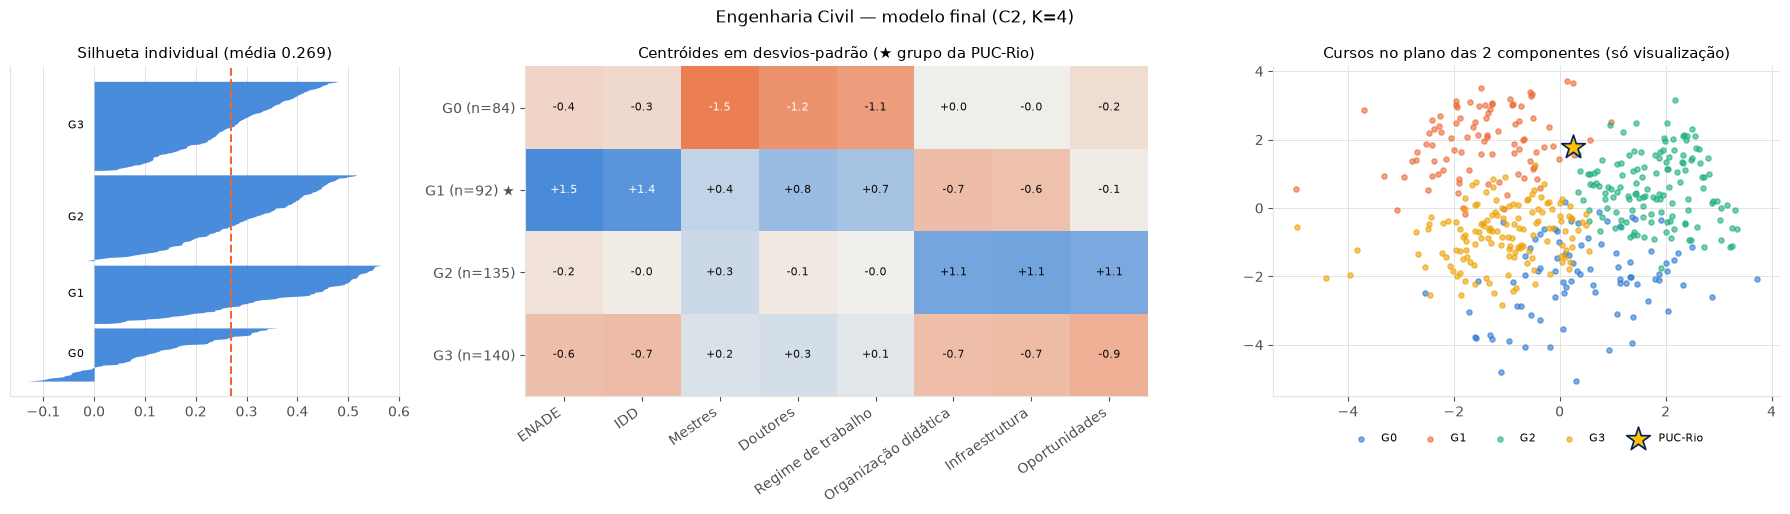

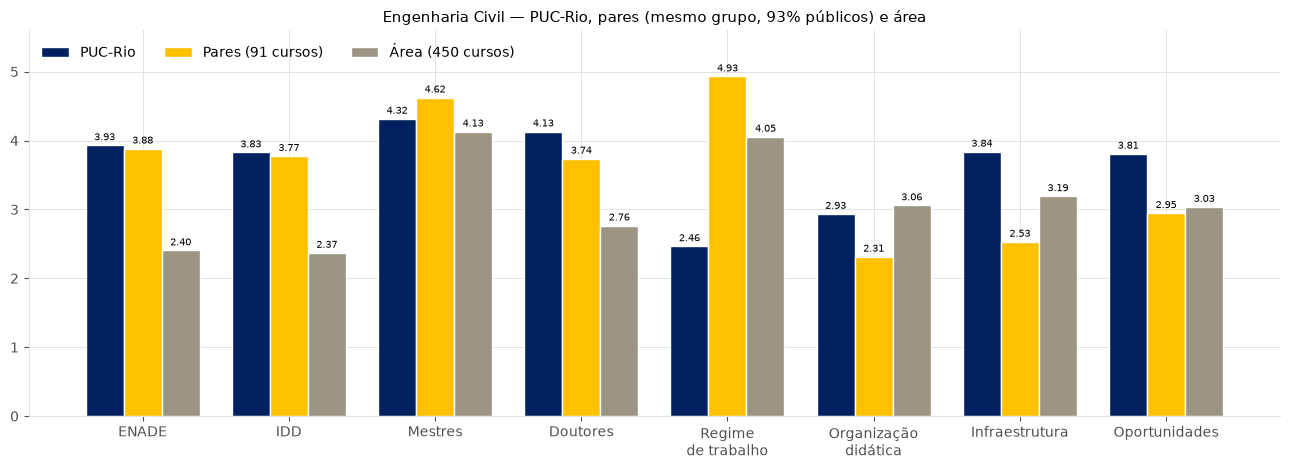

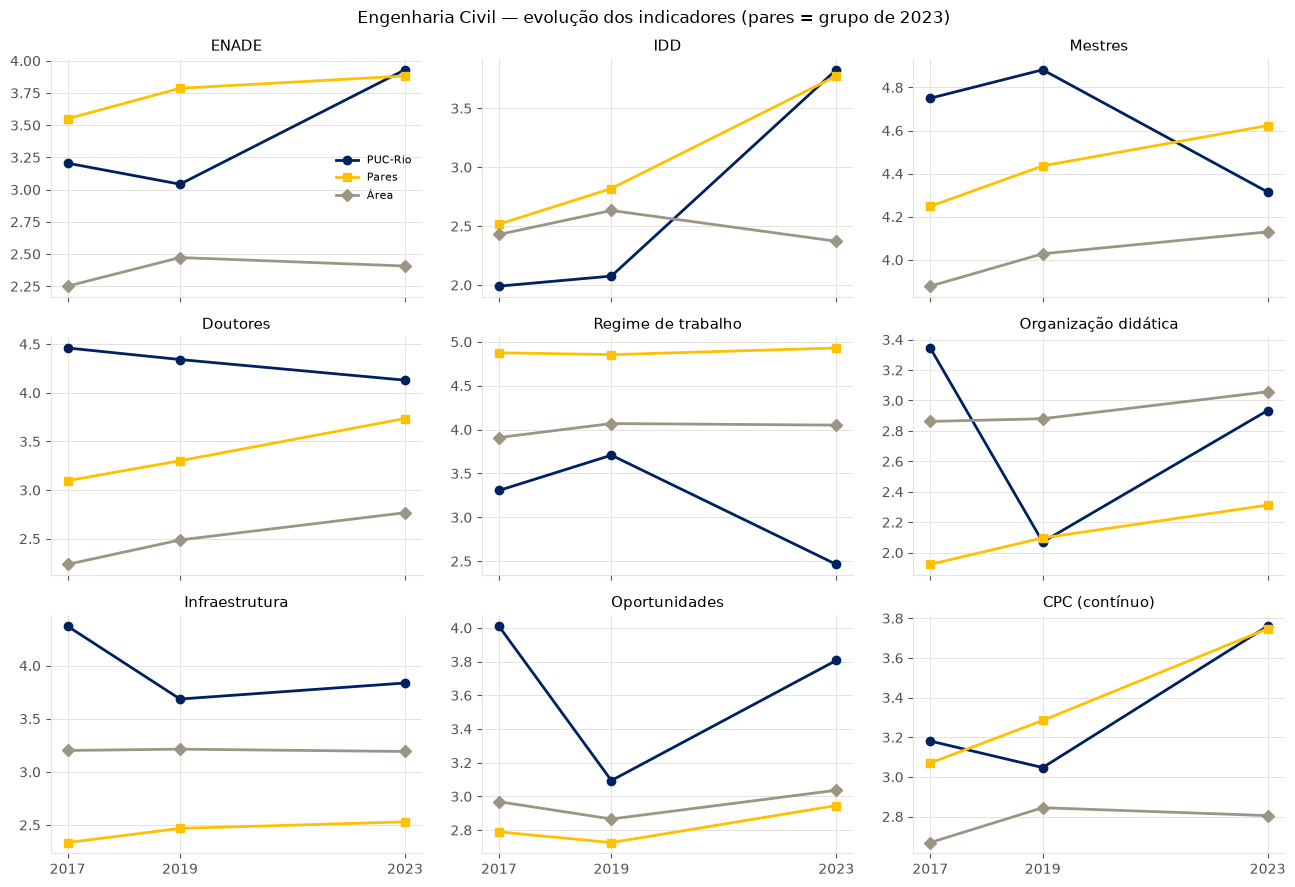

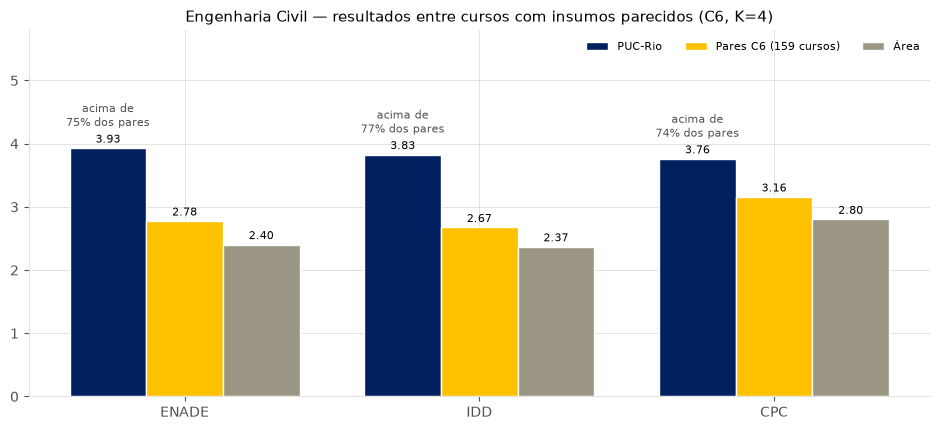

Figuras salvas: 64 em resultados_notebook_09


In [13]:
# Célula 10 — Gráficos de cada área (salvos em resultados_notebook_09/<área>/)

def nome_pasta(codigo):
    return f"{codigo}_" + AREAS[codigo].replace(" ", "_").replace("ç", "c").replace("ã", "a").replace("é", "e")


def figuras_area(codigo, exibir):
    pasta = pasta_saida / nome_pasta(codigo)
    pasta.mkdir(exist_ok=True)
    tab = base_principal[(base_principal["Area"] == codigo)]
    k_esc = k_principal[codigo]
    arquivos = []

    def fechar(fig, nome):
        caminho = pasta / nome
        fig.savefig(caminho, dpi=150, bbox_inches="tight")
        arquivos.append(caminho)
        plt.show() if exibir else plt.close(fig)

    # A — curvas por K: cotovelo, silhueta, Davies–Bouldin, ARI
    fig, eixos = plt.subplots(2, 2, figsize=(13, 8))
    paineis = [("Inercia", "Inércia no treino (cotovelo)"), ("Silhueta_teste", "Silhueta no teste"),
               ("DB_teste", "Davies–Bouldin no teste (menor é melhor)"), ("ARI_medio", "Estabilidade entre divisões (ARI)")]
    for ax, (col, titulo) in zip(eixos.flat, paineis):
        for cen, rotulo in CENARIOS.items():
            t = tab[(tab["Cenario"] == cen) & (tab["Proporcao"] == 1.0)]
            valores = t[col] / t[col].max() if col == "Inercia" else t[col]
            ax.plot(t["K"], valores, marker="o", markersize=5, linewidth=2, color=CORES_CENARIOS[cen], label=rotulo)
        ax.axvline(k_esc, color=COR_TEXTO, linestyle=":", linewidth=1.2)
        ax.set_title(titulo + (" — normalizada" if col == "Inercia" else ""))
        ax.set_xlabel("K"); ax.set_xticks(range(2, K_MAX + 1))
    eixos[0, 0].legend(fontsize=8)
    fig.suptitle(f"{AREAS[codigo]} — métricas por K (100% do treino; pontilhado: K escolhido no C2 = {k_esc})", fontsize=12)
    plt.tight_layout()
    fechar(fig, "A_metricas_por_k.png")

    # B — ganho sobre dados sem grupos
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for cen, rotulo in list(CENARIOS.items())[1:]:
        t = tab[(tab["Cenario"] == cen) & (tab["Proporcao"] == 1.0)]
        ax.plot(t["K"], t["Ganho"], marker="o", linewidth=2, color=CORES_CENARIOS[cen], label=rotulo)
    ax.axhline(0, color=COR_TEXTO, linewidth=0.8)
    ax.axvline(k_esc, color=COR_TEXTO, linestyle=":", linewidth=1.2)
    ax.set_title(f"{AREAS[codigo]} — ganho de silhueta sobre dados simulados sem grupos")
    ax.set_xlabel("K"); ax.set_ylabel("Silhueta real − sem grupos"); ax.legend(fontsize=8)
    ax.set_xticks(range(2, K_MAX + 1))
    plt.tight_layout()
    fechar(fig, "B_ganho_sobre_referencia.png")

    # C — curva de aprendizado: 40%, 70% e 100% do treino, no K escolhido de cada cenário
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
    for cen, rotulo in CENARIOS.items():
        k_c = escolhas[(escolhas["Area"] == codigo) & (escolhas["Cenario"] == cen)]["K_escolhido"].iloc[0]
        t = tab[(tab["Cenario"] == cen) & (tab["K"] == k_c)].sort_values("Proporcao")
        for ax, col in zip(eixos, ["Silhueta_teste", "ARI_medio"]):
            ax.plot(100 * t["Proporcao"], t[col], marker="o", linewidth=2, color=CORES_CENARIOS[cen],
                    label=f"{rotulo} (K={k_c})")
    eixos[0].set_title("Silhueta no teste"); eixos[1].set_title("Estabilidade (ARI)")
    for ax in eixos:
        ax.set_xlabel("% do treino usado"); ax.set_xticks([40, 70, 100])
    eixos[1].legend(fontsize=8)
    fig.suptitle(f"{AREAS[codigo]} — efeito do tamanho da amostra de treino", fontsize=12)
    plt.tight_layout()
    fechar(fig, "C_curva_de_aprendizado.png")

    # D — sensibilidade: escalonadores e algoritmos (C2)
    sens = resumo[(resumo["Area"] == codigo) & (resumo["Cenario"] == CENARIO_PRINCIPAL) & (resumo["Proporcao"] == 1.0)]
    variantes = [("Standard", "K-means"), ("MinMax", "K-means"), ("Robust", "K-means"),
                 ("Standard", "K-medoids"), ("Standard", "Ward")]
    cores_var = ["#123f7a", "#2a78d6", "#7fb2ec", "#eb6834", "#1baf7a"]
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
    for (esc, alg), cor in zip(variantes, cores_var):
        t = sens[(sens["Escalonador"] == esc) & (sens["Algoritmo"] == alg)]
        for ax, col in zip(eixos, ["Silhueta_teste", "ARI_medio"]):
            ax.plot(t["K"], t[col], marker="o", linewidth=2, color=cor, label=f"{alg} + {esc}")
    eixos[0].set_title("Silhueta no teste"); eixos[1].set_title("Estabilidade (ARI)")
    for ax in eixos:
        ax.set_xlabel("K"); ax.axvline(k_esc, color=COR_TEXTO, linestyle=":", linewidth=1.2)
        ax.set_xticks(range(2, K_MAX + 1))
    eixos[1].legend(fontsize=8)
    fig.suptitle(f"{AREAS[codigo]} — sensibilidade ao escalonador e ao algoritmo (C2)", fontsize=12)
    plt.tight_layout()
    fechar(fig, "D_sensibilidade.png")

    # E — modelo final: silhueta por grupo, perfis e mapa em 2D
    info = modelos_finais[codigo]
    dados, grupos, X, sil, pos = info["dados"], info["grupos"], info["X"], info["sil"], info["pos_puc"]
    centros = info["modelo"]["kmeans"].cluster_centers_
    fig, eixos = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1.6, 1.3]})

    base_y = 0
    for g in range(k_esc):
        v = np.sort(sil[grupos == g])
        eixos[0].fill_betweenx(np.arange(base_y, base_y + len(v)), 0, v, color="#2a78d6", alpha=0.85, linewidth=0)
        eixos[0].text(-0.02, base_y + len(v) / 2, f"G{g}", ha="right", va="center", fontsize=8)
        base_y += len(v) + 6
    eixos[0].axvline(sil.mean(), color="#eb6834", linestyle="--")
    eixos[0].set_title(f"Silhueta individual (média {sil.mean():.3f})"); eixos[0].set_yticks([])

    cmap_div = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f1f0ec", "#2a78d6"])
    eixos[1].imshow(centros, cmap=cmap_div, vmin=-1.8, vmax=1.8, aspect="auto")
    for i in range(k_esc):
        for j in range(len(NOMES)):
            eixos[1].text(j, i, f"{centros[i, j]:+.1f}", ha="center", va="center", fontsize=8,
                          color="white" if abs(centros[i, j]) > 1.2 else "#0b0b0b")
    eixos[1].set_xticks(range(len(NOMES)), NOMES, rotation=35, ha="right")
    eixos[1].set_yticks(range(k_esc), [f"G{g} (n={(grupos == g).sum()})" + (" ★" if g == grupos[pos] else "")
                                       for g in range(k_esc)])
    eixos[1].set_title("Centróides em desvios-padrão (★ grupo da PUC-Rio)")
    eixos[1].grid(visible=False)

    pca = PCA(2).fit(X[info["idx_treino"]])
    xy = pca.transform(X)
    paleta = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
    for g in range(k_esc):
        m = grupos == g
        eixos[2].scatter(xy[m, 0], xy[m, 1], s=14, alpha=0.6, color=paleta[g % 8], label=f"G{g}")
    eixos[2].scatter(xy[pos, 0], xy[pos, 1], marker="*", s=320, color="#FFC000", edgecolors="#002060",
                     linewidths=1.2, label="PUC-Rio", zorder=5)
    eixos[2].set_title("Cursos no plano das 2 componentes (só visualização)")
    eixos[2].legend(fontsize=8, ncols=k_esc + 1, loc="upper center", bbox_to_anchor=(0.5, -0.08))
    fig.suptitle(f"{AREAS[codigo]} — modelo final (C2, K={k_esc})", fontsize=12)
    plt.tight_layout()
    fechar(fig, "E_modelo_final.png")

    # F — PUC-Rio × pares × área
    pares = pares_por_area[codigo]
    valores = pd.DataFrame({
        "PUC-Rio": dados.loc[pos, INDICADORES].astype(float).to_numpy(),
        f"Pares ({len(pares)} cursos)": dados.loc[pares, INDICADORES].mean().to_numpy(),
        f"Área ({len(dados) - 1} cursos)": dados.drop(index=pos)[INDICADORES].mean().to_numpy()
    }, index=NOMES)
    fig, ax = plt.subplots(figsize=(13, 4.8))
    largura = 0.26
    for i, (col, cor) in enumerate(zip(valores.columns, [COR_PUC, COR_PARES, COR_AREA])):
        barras = ax.bar(np.arange(len(NOMES)) + (i - 1) * largura, valores[col], largura,
                        color=cor, label=col, edgecolor="white")
        ax.bar_label(barras, fmt="%.2f", fontsize=7, padding=2)
    ax.set_xticks(range(len(NOMES)), [n.replace(" ", "\n", 1) for n in NOMES])
    ax.set_ylim(0, 5.6); ax.legend(ncols=3, loc="upper left")
    publicos = diagnostico.loc[AREAS[codigo], "% públicos nos pares"]
    ax.set_title(f"{AREAS[codigo]} — PUC-Rio, pares (mesmo grupo, {publicos:.0f}% públicos) e área")
    plt.tight_layout()
    fechar(fig, "F_puc_pares_area.png")

    # G — evolução 2017–2019–2023
    ev = evolucao[evolucao["Area"] == codigo]
    fig, eixos = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
    for ax, nome in zip(eixos.flat, NOMES_EVOL):
        t = ev[ev["Indicador"] == nome]
        for col, cor, marcador in [("PUC-Rio", COR_PUC, "o"), ("Pares", COR_PARES, "s"), ("Área", COR_AREA, "D")]:
            ax.plot(t["Ano"], t[col], marker=marcador, linewidth=2, color=cor, label=col)
        ax.set_title(nome); ax.set_xticks(ANOS)
    eixos[0, 0].legend(fontsize=8)
    fig.suptitle(f"{AREAS[codigo]} — evolução dos indicadores (pares = grupo de 2023)", fontsize=12)
    plt.tight_layout()
    fechar(fig, "G_evolucao_2017_2023.png")

    # I — benchmarking com pares de insumos parecidos (C6)
    b = benchmark[benchmark["Area"] == codigo].set_index("Indicador")
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    posicoes = np.arange(len(b))
    for i, (col, rotulo, cor) in enumerate([("PUC-Rio", "PUC-Rio", COR_PUC),
                                            ("Média dos pares", f"Pares C6 ({int(b['Pares'].iloc[0])} cursos)", COR_PARES),
                                            ("Média da área", "Área", COR_AREA)]):
        barras = ax.bar(posicoes + (i - 1) * 0.26, b[col], 0.26, color=cor, label=rotulo, edgecolor="white")
        ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
    for p, (_, linha) in zip(posicoes, b.iterrows()):
        ax.text(p - 0.26, linha["PUC-Rio"] + 0.35, f"acima de\n{linha['Percentil nos pares']:.0f}% dos pares",
                ha="center", fontsize=8, color=COR_TEXTO)
    ax.set_xticks(posicoes, b.index)
    ax.set_ylim(0, 5.8)
    ax.legend(ncols=3, loc="upper right", fontsize=8)
    ax.set_title(f"{AREAS[codigo]} — resultados entre cursos com insumos parecidos (C6, K={int(b['K'].iloc[0])})")
    plt.tight_layout()
    fechar(fig, "I_benchmark_C6.png")

    return arquivos


arquivos_por_area = {}
for codigo in AREAS:
    arquivos_por_area[codigo] = figuras_area(codigo, exibir=codigo in AREAS_EXIBIDAS)

print("Figuras salvas:", sum(len(v) for v in arquivos_por_area.values()), "em", pasta_saida)

### Leitura dos gráficos C e D (todas as áreas)

- **Tamanho do treino (gráfico C):** a silhueta quase não muda entre 40%, 70% e 100%, mas a estabilidade cresce com mais cursos. O ARI passa de 0,76 para 0,95 na Civil e de 0,65 para 0,94 em Arquitetura. O Jaccard dos pares da PUC-Rio em Arquitetura vai de 0,39 para 0,94. Com amostras pequenas, os grupos e os pares são instáveis, e por isso o modelo final usa todo o treino. Em Química e Ambiental, o K escolhido não é viável com 40% do treino, que tem menos de 10 cursos por grupo.
- **Escalonador e algoritmo (gráfico D):** o K-means com StandardScaler tem a maior estabilidade em 5 das 8 áreas e fica próximo do máximo nas outras 3. O RobustScaler às vezes dá silhueta um pouco maior, mas com estabilidade bem menor em Mecânica (0,56) e Química (0,47). Ward e k-medoids são menos estáveis em todas as áreas (ARI de 0,35 a 0,73).

## 7. Exportação e registro no MLflow

No MLflow, cada área tem um registro principal com parâmetros, métricas do modelo final e os sete gráficos. Dentro dele há um registro por combinação de cenário, escalonador, algoritmo e proporção do treino. As métricas desses registros são gravadas por K: na interface, o gráfico da métrica contra o passo (K) mostra a curva do cotovelo, da silhueta ou do ARI. O registro `modelo_final_C2` guarda o modelo treinado (escalonador + K-means), que pode ser recarregado com `mlflow.sklearn.load_model`.

In [14]:
# Célula 11 — Exportar tabelas

tabelas = {
    "log_execucoes.csv": log,
    "resumo_por_configuracao.csv": resumo,
    "k_escolhido_por_area.csv": escolhas,
    "diagnostico_puc_por_area.csv": diagnostico.reset_index(),
    "evolucao_2017_2023.csv": evolucao,
    "validacao_externa_publica_privada.csv": validacao,
    "composicao_pares_puc_C2.csv": composicao_pares.reset_index(),
    "benchmark_C6_insumos.csv": benchmark
}
for nome, tabela in tabelas.items():
    tabela.to_csv(pasta_saida / nome, index=False, sep=";", decimal=",", encoding="utf-8-sig")
print("Tabelas exportadas:", list(tabelas))

Tabelas exportadas: ['log_execucoes.csv', 'resumo_por_configuracao.csv', 'k_escolhido_por_area.csv', 'diagnostico_puc_por_area.csv', 'evolucao_2017_2023.csv', 'validacao_externa_publica_privada.csv', 'composicao_pares_puc_C2.csv', 'benchmark_C6_insumos.csv']


In [15]:
# Célula 12 — Registro no MLflow

banco = Path("mlflow_cpc.db").resolve()
mlflow.set_tracking_uri("sqlite:///" + banco.as_posix())
EXPERIMENTO = EXPERIMENTO_MLFLOW
if mlflow.get_experiment_by_name(EXPERIMENTO) is None:
    mlflow.create_experiment(EXPERIMENTO, artifact_location=Path("mlartifacts").resolve().as_uri())
mlflow.set_experiment(EXPERIMENTO)

inicio = time.time()
execucao = time.strftime("%Y-%m-%d %H:%M")
METRICAS_K = {"Silhueta_treino": "silhueta_treino", "Silhueta_teste": "silhueta_teste",
              "DB_teste": "davies_bouldin_teste", "Inercia": "inercia", "ARI_medio": "ari_medio",
              "Jaccard_PUC": "jaccard_pares_puc", "Ganho": "ganho_sobre_referencia"}

for codigo in AREAS:
    d = diagnostico.loc[AREAS[codigo]]
    with mlflow.start_run(run_name=f"{codigo} · {AREAS[codigo]}", tags={"execucao": execucao, "nivel": "area"}):
        mlflow.log_params({
            "area_codigo": codigo, "area_nome": AREAS[codigo], "cursos": int(resumo_areas.loc[codigo, "Cursos"]),
            "curso_puc": int(d["Curso PUC"]), "k_escolhido_C2": int(d["K"]), "divisoes": len(SEMENTES),
            "proporcoes": str(PROPORCOES), "regra_k": f"ARI>={LIMIAR_ARI} e maior ganho"
        })
        mlflow.log_metrics({
            "modelo_final_silhueta_teste": float(d["Silhueta teste"]),
            "modelo_final_db_teste": float(d["DB teste"]),
            "puc_silhueta": float(d["Silhueta PUC"]),
            "puc_regime_menos_pares": float(d["Regime − pares"]),
            "puc_regime_menos_privadas": float(d["Regime − privadas da área"])
        })
        for arquivo in arquivos_por_area[codigo]:
            mlflow.log_artifact(str(arquivo), artifact_path="graficos")

        grupos_cfg = resumo[resumo["Area"] == codigo].groupby(["Cenario", "Escalonador", "Algoritmo", "Proporcao"])
        for (cen, esc, alg, prop), t in grupos_cfg:
            tipo = "principal" if (esc == "Standard" and alg == "K-means") else "sensibilidade"
            nome = f"{cen} · {alg} · {esc} · {int(prop * 100)}%"
            with mlflow.start_run(run_name=nome, nested=True, tags={"execucao": execucao, "tipo": tipo}):
                mlflow.log_params({"cenario": cen, "escalonador": esc, "algoritmo": alg,
                                   "proporcao_treino": prop, "n_treino": int(t["N_treino"].iloc[0])})
                for _, linha in t.sort_values("K").iterrows():
                    for col, chave in METRICAS_K.items():
                        if pd.notna(linha[col]):
                            mlflow.log_metric(chave, float(linha[col]), step=int(linha["K"]))

        with mlflow.start_run(run_name="modelo_final_C2", nested=True, tags={"execucao": execucao, "tipo": "modelo"}):
            mlflow.log_params({"cenario": CENARIO_PRINCIPAL, "k": int(d["K"]), "treino": "80%", "semente": SEMENTES[0]})
            mlflow.log_metrics({"silhueta_teste": float(d["Silhueta teste"]), "db_teste": float(d["DB teste"])})
            mlflow.sklearn.log_model(modelos_finais[codigo]["modelo"], name="modelo")

        with mlflow.start_run(run_name="modelo_benchmark_C6", nested=True, tags={"execucao": execucao, "tipo": "modelo"}):
            b = benchmark[benchmark["Area"] == codigo].set_index("Indicador")
            mlflow.log_params({"cenario": CENARIO_BENCHMARK, "k": int(b["K"].iloc[0]), "treino": "80%",
                               "semente": SEMENTES[0], "pares": int(b["Pares"].iloc[0])})
            mlflow.log_metrics({f"puc_menos_pares_{i.lower()}": float(b.loc[i, "Diferença"]) for i in b.index})
            mlflow.sklearn.log_model(modelos_c6[codigo], name="modelo")

with mlflow.start_run(run_name="Visão geral", tags={"execucao": execucao, "nivel": "geral"}):
    mlflow.log_artifact(str(pasta_saida / "figura_1_visao_geral_areas.png"), artifact_path="graficos")
    mlflow.log_artifact(str(pasta_saida / "figura_2_validacao_externa.png"), artifact_path="graficos")
    for nome in tabelas:
        mlflow.log_artifact(str(pasta_saida / nome), artifact_path="tabelas")

print(f"Registro concluído em {(time.time() - inicio) / 60:.1f} min")
print("Experimento:", EXPERIMENTO)
print("Para abrir a interface, rode no terminal, na pasta do projeto:")
print('python -m mlflow ui --backend-store-uri "sqlite:///mlflow_cpc.db"')
print("e acesse http://127.0.0.1:5000")

Registro concluído em 74.8 min
Experimento: CPC2023_agrupamento_por_area_C1_C7
Para abrir a interface, rode no terminal, na pasta do projeto:
python -m mlflow ui --backend-store-uri "sqlite:///mlflow_cpc.db"
e acesse http://127.0.0.1:5000


## 8. Limitações

- As 10 divisões compartilham cursos, então não são amostras independentes.
- Em áreas pequenas, o teste tem de 19 a 22 cursos, e as métricas no teste variam mais.
- A referência sem grupos é uma hipótese de trabalho, não um teste estatístico.
- A evolução usa os grupos de 2023 para definir os pares; ela não reagrupa os cursos em 2017 e 2019.
- Os resultados são descritivos e não identificam causas.